# Transformer NMT with Pretrained Embeddings: FastText vs BPEmb (English → Gujarati)
### Introduction to Large Language Models — Assignment 9

We train two English → Gujarati Transformer models with
[OpenNMT-py](https://github.com/OpenNMT/OpenNMT-py) on the same data as Assignment 8 and evaluate them
with [sacreBLEU](https://github.com/mjpost/sacrebleu), overall and per length bin. The two models differ
only in how words are represented and in the pretrained vectors used to initialise their embedding layers:

1. **FastText embeddings** ([pretrained wiki vectors](https://fasttext.cc/docs/en/pretrained-vectors.html),
   300-d, `wiki.en.vec` and `wiki.gu.vec`): a **word-level** model. Each word in the vocabulary
   starts from its FastText vector.
2. **Subword embeddings** ([BPEmb](https://github.com/bheinzerling/bpemb), 10k BPE vocabulary, 300-d): the
   text is first segmented into subwords with BPEmb's own SentencePiece BPE models, and each subword
   starts from its BPEmb vector.

**Data.** The exact train / valid / test files from Assignment 8 (`ilci` subset of
[BPCC](https://huggingface.co/datasets/ai4bharat/BPCC), English → Gujarati, stratified by source length into
4 bins with 1,000 test sentences per bin):

| Bin | Source length $n$ |
|---|---|
| bin1 | $n \le 10$ |
| bin2 | $10 < n \le 20$ |
| bin3 | $20 < n < 30$ |
| bin4 | $n \ge 30$ |

Reusing the same splits makes both models directly comparable with each other and with the Assignment 8
baseline (randomly initialised embeddings over a SentencePiece vocabulary learnt on the training data).

## 0. Setup

Run in the `nlp` conda environment (OpenNMT-py was installed there for Assignment 8). `bpemb` is the
only new package.

In [1]:
# %pip install -q bpemb

In [2]:
import os
import re
import sys
import glob
import subprocess
import urllib.request
import warnings

warnings.filterwarnings("ignore", category=FutureWarning)
# torch >= 2.6 defaults torch.load(weights_only=True), which cannot load OpenNMT-py 3.x checkpoints
os.environ["TORCH_FORCE_NO_WEIGHTS_ONLY_LOAD"] = "1"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import yaml
import sacrebleu
import onmt
from bpemb import BPEmb

print("torch", torch.__version__, "| OpenNMT-py", onmt.__version__, "| sacreBLEU", sacrebleu.__version__)

RANDOM_SEED = 42
SRC_LANG, TGT_LANG = "en", "gu"

LAB8_DATA = "../Lab-8/lab8_artifacts/data"          # splits created in Assignment 8
LAB8_RESULTS = "../Lab-8/lab8_artifacts/run/binwise_results.csv"
ART = "lab9_artifacts"
EMB_DIR = f"{ART}/embeddings"
os.makedirs(EMB_DIR, exist_ok=True)

BINS = ["bin1", "bin2", "bin3", "bin4"]
BIN_LABELS = {"bin1": "n ≤ 10", "bin2": "10 < n ≤ 20", "bin3": "20 < n < 30", "bin4": "n ≥ 30"}

EMB_DIM = 300             # FastText wiki vectors and the chosen BPEmb vectors are both 300-d
WORD_VOCAB_SIZE = 30000   # word-level vocabulary per language for the FastText model
BPEMB_VS = 10000          # BPEmb vocabulary size
FASTTEXT_MAX_LINES = 1_000_000  # read only the 1M most frequent words of wiki.en.vec (the file has 2.5M, 6.6 GB)

USE_GPU = torch.cuda.is_available()   # OpenNMT-py 3.x trains on CUDA or CPU (no MPS backend)
TRAIN_STEPS = 20000                   # same as the Assignment 8 baseline; ~6 h per model on an Apple M4 CPU
print("CUDA available:", USE_GPU, "| train steps per model:", TRAIN_STEPS)

torch 2.14.0 | OpenNMT-py 3.5.1 | sacreBLEU 2.6.0
CUDA available: False | train steps per model: 20000


In [3]:
def run(cmd):
    # Run an OpenNMT-py command line tool with this kernel's interpreter and stream its log.
    print("$", " ".join(cmd))
    proc = subprocess.Popen([sys.executable, "-m"] + cmd, stdout=subprocess.PIPE,
                            stderr=subprocess.STDOUT, text=True, env=os.environ.copy())
    for line in proc.stdout:
        if "Warning" not in line and "@custom_" not in line and "warnings.warn" not in line:
            print(line, end="")
    if proc.wait() != 0:
        raise RuntimeError(f"command failed with exit code {proc.returncode}")


def read_lines(path):
    with open(path, encoding="utf-8") as f:
        return f.read().splitlines()


def write_lines(path, lines):
    with open(path, "w", encoding="utf-8") as f:
        for line in lines:
            f.write(line + "\n")

## 1. Load the Assignment 8 splits

In [4]:
splits = {}
for name in ("train", "valid", "test"):
    splits[name] = pd.DataFrame({
        "src": read_lines(f"{LAB8_DATA}/{name}.{SRC_LANG}"),
        "tgt": read_lines(f"{LAB8_DATA}/{name}.{TGT_LANG}"),
        "bin": read_lines(f"{LAB8_DATA}/{name}.bin"),
    })
    splits[name]["src_len"] = splits[name].src.str.split().str.len()

counts = pd.DataFrame({k: v.bin.value_counts() for k, v in splits.items()}).loc[BINS]
counts.insert(0, "length", [BIN_LABELS[b] for b in BINS])
counts.loc["total"] = ["", *counts[["train", "valid", "test"]].sum()]
counts

,length,train,valid,test
bin,,,,
bin1,n ≤ 10,16983,200,1000
bin2,10 < n ≤ 20,50478,200,1000
bin3,20 < n < 30,21285,200,1000
bin4,n ≥ 30,7951,200,1000
total,,96697,800,4000


## 2. Shared model configuration, training and evaluation helpers

Both models use the same Transformer: 4 encoder and 4 decoder layers, model size 300 (it must equal the
embedding size), 4 attention heads, feed-forward size 1024, dropout 0.2, label smoothing 0.1, and Adam
with the Noam schedule. The pretrained vectors only **initialise** the embedding layers and are
fine-tuned during training. Tokens with no pretrained vector (and the special tokens) start from
random values.

In [5]:
def make_config(run_dir, data_dir, src_vocab_size, tgt_vocab_size, src_emb=None, tgt_emb=None):
    cfg = {
        "save_data": f"{run_dir}/data",
        "src_vocab": f"{run_dir}/vocab.{SRC_LANG}",
        "tgt_vocab": f"{run_dir}/vocab.{TGT_LANG}",
        "src_vocab_size": src_vocab_size,
        "tgt_vocab_size": tgt_vocab_size,
        "src_words_min_frequency": 2,
        "tgt_words_min_frequency": 2,
        "overwrite": True,
        "share_vocab": False,
        "data": {
            "corpus_1": {"path_src": f"{data_dir}/train.{SRC_LANG}", "path_tgt": f"{data_dir}/train.{TGT_LANG}",
                         "transforms": ["filtertoolong"]},
            "valid": {"path_src": f"{data_dir}/valid.{SRC_LANG}", "path_tgt": f"{data_dir}/valid.{TGT_LANG}"},
        },
        "src_seq_length": 200,
        "tgt_seq_length": 200,

        # model
        "model_task": "seq2seq",
        "encoder_type": "transformer",
        "decoder_type": "transformer",
        "enc_layers": 4,
        "dec_layers": 4,
        "hidden_size": EMB_DIM,
        "word_vec_size": EMB_DIM,
        "transformer_ff": 1024,
        "heads": 4,
        "position_encoding": True,
        "dropout": [0.2],
        "attention_dropout": [0.1],
        "share_decoder_embeddings": True,

        # optimisation
        "seed": RANDOM_SEED,
        "train_steps": TRAIN_STEPS,
        "valid_steps": 1000,
        "early_stopping": 4,
        "save_model": f"{run_dir}/model",
        "save_checkpoint_steps": 1000,
        "keep_checkpoint": 3,
        "report_every": 200,
        "batch_type": "tokens",
        "batch_size": 4096,
        "valid_batch_size": 2048,
        "accum_count": [1],
        "optim": "adam",
        "adam_beta2": 0.998,
        "decay_method": "noam",
        "learning_rate": 2.0,
        "warmup_steps": 2000,
        "max_grad_norm": 0.0,
        "label_smoothing": 0.1,
        "param_init": 0.0,
        "param_init_glorot": True,
        "normalization": "tokens",
        "bucket_size": 32768,
        "num_workers": 0,
        "world_size": 1,
        "gpu_ranks": [0] if USE_GPU else [],
    }
    if src_emb or tgt_emb:
        cfg["embeddings_type"] = "word2vec"
        if src_emb:
            cfg["src_embeddings"] = src_emb
        if tgt_emb:
            cfg["tgt_embeddings"] = tgt_emb
    path = f"{run_dir}/config.yaml"
    with open(path, "w") as f:
        yaml.safe_dump(cfg, f, sort_keys=False, allow_unicode=True)
    return path


def read_vocab(path, size, min_freq=2):
    # OpenNMT-py vocab files list every counted token as "token<TAB>count", most frequent first;
    # the model keeps the first `size` tokens seen at least `min_freq` times
    toks = []
    for line in read_lines(path):
        tok, count = line.rsplit("\t", 1)
        if int(count) >= min_freq:
            toks.append(tok)
    return toks[:size]


def write_w2v(path, vectors):
    # word2vec text format: header "count dim", then "token v1 ... vd" per line
    with open(path, "w", encoding="utf-8") as f:
        f.write(f"{len(vectors)} {EMB_DIM}\n")
        for tok, vec in vectors.items():
            f.write(tok + " " + " ".join(f"{x:.5f}" for x in vec) + "\n")


def latest_checkpoint(run_dir):
    ckpts = sorted(glob.glob(f"{run_dir}/model_step_*.pt"),
                   key=lambda p: int(re.search(r"step_(\d+)", p).group(1)))
    print("checkpoints kept:", [os.path.basename(p) for p in ckpts])
    return ckpts[-1]


def translate(run_dir, src_path, out_path):
    cmd = ["onmt.bin.translate", "-model", latest_checkpoint(run_dir), "-src", src_path, "-output", out_path,
           "-beam_size", "5", "-batch_size", "2048", "-batch_type", "tokens", "-max_length", "250",
           "-report_time"]
    if USE_GPU:
        cmd += ["-gpu", "0"]
    run(cmd)
    return read_lines(out_path)


def scores(frame, hyp_col):
    hyps, refs = list(frame[hyp_col]), [list(frame.tgt)]
    bleu = sacrebleu.corpus_bleu(hyps, refs, force=True)  # ILCI text is pre-tokenized
    chrf = sacrebleu.corpus_chrf(hyps, refs)
    return {"BLEU": round(bleu.score, 2), "chrF": round(chrf.score, 2),
            "1/2/3/4-gram prec.": "/".join(f"{p:.1f}" for p in bleu.precisions),
            "BP": round(bleu.bp, 3)}


def binwise(frame, hyp_col):
    rows = {b: {"length": BIN_LABELS[b], **scores(frame[frame.bin == b], hyp_col)} for b in BINS}
    rows["overall"] = {"length": "all", **scores(frame, hyp_col)}
    return pd.DataFrame(rows).T

## 3. Model 1 — word-level Transformer with FastText embeddings

### 3.1 Word vocabulary

ILCI text is already tokenised (punctuation is separated by spaces), so tokens are whitespace-separated
words. The FastText wiki vectors are **lowercased**, so the English side is lowercased to match. Gujarati
has no case. Each side keeps the 30,000 most frequent training words (seen at least twice); all other
words become `<unk>`.

In [6]:
FT_DATA = f"{ART}/fasttext/data"
FT_RUN = f"{ART}/fasttext/run"
os.makedirs(FT_DATA, exist_ok=True)
os.makedirs(FT_RUN, exist_ok=True)

for name, s in splits.items():
    write_lines(f"{FT_DATA}/{name}.{SRC_LANG}", s.src.str.lower())
    write_lines(f"{FT_DATA}/{name}.{TGT_LANG}", s.tgt)

ft_config = make_config(FT_RUN, FT_DATA, WORD_VOCAB_SIZE, WORD_VOCAB_SIZE)
run(["onmt.bin.build_vocab", "-config", ft_config, "-n_sample", "-1"])
ft_vocab = {lang: read_vocab(f"{FT_RUN}/vocab.{lang}", WORD_VOCAB_SIZE) for lang in (SRC_LANG, TGT_LANG)}
print({k: len(v) for k, v in ft_vocab.items()})

$ onmt.bin.build_vocab -config lab9_artifacts/fasttext/run/config.yaml -n_sample -1
Corpus corpus_1's weight should be given. We default it to 1 for you.
[2026-11-04 15:57:45,735 INFO] Counter vocab from -1 samples.
[2026-11-04 15:57:45,735 INFO] n_sample=-1: Build vocab on full datasets.
[2026-11-04 15:57:47,962 INFO] Counters src: 76400
[2026-11-04 15:57:47,962 INFO] Counters tgt: 128606
{'en': 30000, 'gu': 30000}


In [7]:
def oov_rate(frame, col, vocab, lower=False):
    vocab = set(vocab)
    toks = [t for s in frame[col] for t in (s.lower() if lower else s).split()]
    return 100 * sum(t not in vocab for t in toks) / len(toks)

oov = pd.DataFrame({
    "src OOV % (en)": [oov_rate(splits["test"][splits["test"].bin == b], "src", ft_vocab["en"], lower=True) for b in BINS],
    "tgt OOV % (gu)": [oov_rate(splits["test"][splits["test"].bin == b], "tgt", ft_vocab["gu"]) for b in BINS],
}, index=BINS).round(2)
print("Test tokens outside the 30k word vocabularies (they become <unk>):")
oov

Test tokens outside the 30k word vocabularies (they become <unk>):


,src OOV % (en),tgt OOV % (gu)
bin1,3.99,8.79
bin2,4.07,9.61
bin3,3.92,9.92
bin4,5.14,10.77


### 3.2 Load the FastText vectors

The `.vec` files are plain text sorted by word frequency (`wiki.gu.vec`: 74,632 words, 198 MB;
`wiki.en.vec`: 2.5M words, 6.6 GB). We stream each file and keep only the vectors of words in our
vocabulary. For English we stop after the 1M most frequent words, which covers almost all of our
vocabulary. The filtered vectors are saved in word2vec text format, which OpenNMT-py reads with
`embeddings_type: word2vec`.

In [8]:
def filter_fasttext(lang, vocab, out_path, max_lines=None):
    if os.path.exists(out_path):
        print("using cached", out_path)
        return
    url = f"https://dl.fbaipublicfiles.com/fasttext/vectors-wiki/wiki.{lang}.vec"
    wanted, found = set(vocab), {}
    with urllib.request.urlopen(url) as r:
        n_words, dim = map(int, r.readline().split())
        assert dim == EMB_DIM
        for i, raw in enumerate(r):
            if max_lines and i >= max_lines:
                break
            parts = raw.decode("utf-8", errors="ignore").rstrip().split(" ")
            if len(parts) != EMB_DIM + 1 or parts[0] not in wanted:
                continue
            found[parts[0]] = [float(x) for x in parts[1:]]
            if len(found) == len(wanted):
                break
            if i % 200_000 == 0 and i:
                print(f"  {lang}: read {i:,} lines, matched {len(found):,} / {len(wanted):,}")
    write_w2v(out_path, found)
    print(f"{lang}: {len(found):,} of {len(wanted):,} vocabulary words have a FastText vector")

FT_EMB = {lang: f"{EMB_DIR}/fasttext.{lang}.vec" for lang in (SRC_LANG, TGT_LANG)}
filter_fasttext("gu", ft_vocab["gu"], FT_EMB["gu"])
filter_fasttext("en", ft_vocab["en"], FT_EMB["en"], max_lines=FASTTEXT_MAX_LINES)

using cached lab9_artifacts/embeddings/fasttext.gu.vec
using cached lab9_artifacts/embeddings/fasttext.en.vec


In [9]:
def coverage(vocab, vec_path):
    with open(vec_path, encoding="utf-8") as f:
        next(f)
        have = {line.split(" ", 1)[0] for line in f}
    real = [t for t in vocab if not (t.startswith("<") and t.endswith(">"))]
    return len(real), sum(t in have for t in real)

cov_rows = {}
for lang in (SRC_LANG, TGT_LANG):
    n, k = coverage(ft_vocab[lang], FT_EMB[lang])
    cov_rows[lang] = {"vocab": n, "with pretrained vector": k, "coverage %": round(100 * k / n, 1)}
pd.DataFrame(cov_rows).T

,vocab,with pretrained vector,coverage %
en,30000.0,21655.0,72.2
gu,30000.0,19886.0,66.3


### 3.3 Train

In [10]:
ft_config = make_config(FT_RUN, FT_DATA, WORD_VOCAB_SIZE, WORD_VOCAB_SIZE,
                        src_emb=FT_EMB["en"], tgt_emb=FT_EMB["gu"])
run(["onmt.bin.train", "-config", ft_config])

$ onmt.bin.train -config lab9_artifacts/fasttext/run/config.yaml
[2026-11-04 15:57:49,424 WARNING] Corpus corpus_1's weight should be given. We default it to 1 for you.
[2026-11-04 15:57:49,424 INFO] Missing transforms field for valid data, set to default: [].
[2026-11-04 15:57:49,424 INFO] Parsed 2 corpora from -data.
[2026-11-04 15:57:49,424 INFO] Get special vocabs from Transforms: {'src': [], 'tgt': []}.
[2026-11-04 15:57:49,499 INFO] Reading encoder embeddings from lab9_artifacts/embeddings/fasttext.en.vec
[2026-11-04 15:57:50,139 INFO] 	Found 38248 total vectors in file.
[2026-11-04 15:57:50,139 INFO] Reading decoder embeddings from lab9_artifacts/embeddings/fasttext.gu.vec
[2026-11-04 15:57:50,740 INFO] 	Found 34308 total vectors in file
[2026-11-04 15:57:50,740 INFO] After filtering to vectors in vocab:
[2026-11-04 15:57:50,744 INFO] 	* enc: 21653 match, 8347 missing, (72.18%)
[2026-11-04 15:57:50,749 INFO] 	* dec: 19886 match, 10114 missing, (66.29%)
[2026-11-04 15:57:50,750 I

### 3.4 Translate the test set

The output is a sequence of words, which is already in the tokenised ILCI format of the references.
Target words outside the vocabulary are produced as `<unk>`; we remove them before scoring (they can
never match the reference anyway) and report how often they occur.

In [11]:
test = splits["test"].copy()
ft_out = translate(FT_RUN, f"{FT_DATA}/test.{SRC_LANG}", f"{FT_RUN}/pred.{TGT_LANG}")
assert len(ft_out) == len(test)
test["unk_fasttext"] = [h.split().count("<unk>") for h in ft_out]
test["hyp_fasttext"] = [" ".join(t for t in h.split() if t != "<unk>") for h in ft_out]
print("<unk> tokens per bin:", test.groupby("bin").unk_fasttext.sum().to_dict())
test[["bin", "src", "tgt", "hyp_fasttext"]].head()

checkpoints kept: ['model_step_7000.pt', 'model_step_8000.pt', 'model_step_9000.pt']
$ onmt.bin.translate -model lab9_artifacts/fasttext/run/model_step_9000.pt -src lab9_artifacts/fasttext/data/test.en -output lab9_artifacts/fasttext/run/pred.gu -beam_size 5 -batch_size 2048 -batch_type tokens -max_length 250 -report_time
[2026-11-04 20:09:22,000 INFO] Loading checkpoint from lab9_artifacts/fasttext/run/model_step_9000.pt
  checkpoint = torch.load(ckpt_path, map_location=torch.device("cpu"))
[2026-11-04 20:09:22,777 INFO] Loading data into the model
[2026-11-04 20:11:06,093 INFO] PRED SCORE: -0.9251, PRED PPL: 2.52 NB SENTENCES: 4000
[2026-11-04 20:11:06,094 INFO] Total translation time (s): 103.3
[2026-11-04 20:11:06,094 INFO] Average translation time (ms): 25.8
[2026-11-04 20:11:06,094 INFO] Tokens per second: 692.5
Time w/o python interpreter load/terminate:  104.10890007019043
<unk> tokens per bin: {'bin1': 1042, 'bin2': 2515, 'bin3': 4258, 'bin4': 8023}


,bin,src,tgt,hyp_fasttext
0,bin1,Chest remains constricted .,છાતી સંકોચાયેલી રહે છે .,છાતી રહે છે .
1,bin4,In the last 2-3 decades changes brought about ...,"છેલ્લા બે - ત્રણ દાયકાઓમાં જીવનશૈલી , ખાન - પા...",છેલ્લા ૨ - ૩ દાયકા દરમિયાન જીવનશૈલીમાં પરિવર્ત...
2,bin1,Nose will stop bleeding .,નાકમાંથી લોહી નીકળવાનું બંધ થઈ જશે .,નાક બંધ થઈ જશે .
3,bin4,"On the other side , for ideological battle wit...","ત્યાં , સોવિયેટ સંઘ અને સમાજવાદી દેશના પ્રસારણ...",બીજી બાજુ સોવિયેટ સંઘે અમેરિકા અને સમાજવાદી દે...
4,bin3,The arm of the east is extending more towards ...,પૂર્વની ભુજા થોડી વધારે આગળ નીકળેલી છે અને તેન...,પૂર્વ તરફ ફેલાયેલા હાથને સામે વધારેમાં વધારે ત...


In [12]:
res_fasttext = binwise(test, "hyp_fasttext")
res_fasttext

,length,BLEU,chrF,1/2/3/4-gram prec.,BP
bin1,n ≤ 10,15.43,31.46,52.3/27.3/13.9/8.2,0.767
bin2,10 < n ≤ 20,9.17,27.19,42.8/18.6/7.6/3.6,0.756
bin3,20 < n < 30,7.23,25.06,39.9/15.5/6.1/2.6,0.729
bin4,n ≥ 30,5.24,22.31,35.6/11.8/4.1/1.6,0.723
overall,all,7.69,25.08,40.4/16.0/6.4/2.9,0.737


## 4. Model 2 — subword Transformer with BPEmb embeddings

### 4.1 Encode the text into subwords with BPEmb

[BPEmb](https://github.com/bheinzerling/bpemb) provides a SentencePiece BPE model and matching 300-d
subword vectors for each language, trained on Wikipedia. As the repository shows, the text is first
segmented with `bpemb.encode`, and those subwords are the tokens of the model.

BPEmb's default preprocessing lowercases the text **and replaces every digit with `0`**
(`૬થી ૧૩` → `0થી 00`). That is fine for learning embeddings, but in translation it would destroy every
number in the output. So we pass `preprocess=False` and lowercase the English ourselves, which keeps
the digits intact. Digits are then split into single-character pieces.

In [13]:
BP_DATA = f"{ART}/bpemb/data"
BP_RUN = f"{ART}/bpemb/run"
os.makedirs(BP_DATA, exist_ok=True)
os.makedirs(BP_RUN, exist_ok=True)

bpemb = {
    SRC_LANG: BPEmb(lang="en", vs=BPEMB_VS, dim=EMB_DIM, preprocess=False),
    TGT_LANG: BPEmb(lang="gu", vs=BPEMB_VS, dim=EMB_DIM, preprocess=False),
}

def bpe_encode(lang, text):
    return " ".join(bpemb[lang].encode(text.lower() if lang == SRC_LANG else text))

def bpe_decode(pieces):
    return "".join(pieces.split()).replace("▁", " ").strip()

for name, s in splits.items():
    write_lines(f"{BP_DATA}/{name}.{SRC_LANG}", (bpe_encode(SRC_LANG, x) for x in s.src))
    write_lines(f"{BP_DATA}/{name}.{TGT_LANG}", (bpe_encode(TGT_LANG, x) for x in s.tgt))

ex = splits["train"].iloc[0]
print(ex.src, "\n ->", bpe_encode(SRC_LANG, ex.src))
print(ex.tgt, "\n ->", bpe_encode(TGT_LANG, ex.tgt))
assert bpe_decode(bpe_encode(TGT_LANG, ex.tgt)) == ex.tgt

This disease may occur with great speed in the age of 6 to 13 years . 
 -> ▁this ▁disease ▁may ▁occur ▁with ▁great ▁speed ▁in ▁the ▁age ▁of ▁ 6 ▁to ▁ 13 ▁years ▁.
૬થી ૧૩ વર્ષની ઉંમરમાં આ બીમારી અચાનક ખૂબ ઝડપથી થઈ શકે છે . 
 -> ▁૬ થી ▁૧૩ ▁વર્ષની ▁ઉંમ રમાં ▁આ ▁બીમારી ▁અચાનક ▁ખૂબ ▁ઝડપથી ▁થઈ ▁શકે ▁છે ▁.


In [14]:
seg = pd.DataFrame({
    "words / sentence (en)": splits["train"].src.str.split().str.len().mean(),
    "subwords / sentence (en)": pd.Series(read_lines(f"{BP_DATA}/train.{SRC_LANG}")).str.split().str.len().mean(),
    "words / sentence (gu)": splits["train"].tgt.str.split().str.len().mean(),
    "subwords / sentence (gu)": pd.Series(read_lines(f"{BP_DATA}/train.{TGT_LANG}")).str.split().str.len().mean(),
}, index=["train"]).round(2)
seg

,words / sentence (en),subwords / sentence (en),words / sentence (gu),subwords / sentence (gu)
train,17.68,24.04,15.85,24.17


### 4.2 Vocabulary and BPEmb vectors

The OpenNMT-py vocabulary is built from the segmented training data, so it contains the BPEmb pieces
that actually occur. Every BPEmb piece has a vector. The only tokens without one are the
special tokens, plus a few characters that BPEmb treats as unknown (for example Gujarati digits, which
its model never saw because they were replaced by `0` during BPEmb training).

In [15]:
bp_config = make_config(BP_RUN, BP_DATA, BPEMB_VS + 1000, BPEMB_VS + 1000)
run(["onmt.bin.build_vocab", "-config", bp_config, "-n_sample", "-1"])
bp_vocab = {lang: read_vocab(f"{BP_RUN}/vocab.{lang}", BPEMB_VS + 1000) for lang in (SRC_LANG, TGT_LANG)}

BP_EMB = {lang: f"{EMB_DIR}/bpemb.{lang}.vec" for lang in (SRC_LANG, TGT_LANG)}
cov_rows = {}
for lang in (SRC_LANG, TGT_LANG):
    kv = bpemb[lang].emb   # gensim KeyedVectors
    write_w2v(BP_EMB[lang], {t: kv[t] for t in bp_vocab[lang] if t in kv.key_to_index})
    n, k = coverage(bp_vocab[lang], BP_EMB[lang])
    cov_rows[lang] = {"vocab": n, "with pretrained vector": k, "coverage %": round(100 * k / n, 1)}
pd.DataFrame(cov_rows).T

$ onmt.bin.build_vocab -config lab9_artifacts/bpemb/run/config.yaml -n_sample -1
Corpus corpus_1's weight should be given. We default it to 1 for you.
[2026-11-04 20:11:14,834 INFO] Counter vocab from -1 samples.
[2026-11-04 20:11:14,834 INFO] n_sample=-1: Build vocab on full datasets.
[2026-11-04 20:11:17,171 INFO] Counters src: 10031
[2026-11-04 20:11:17,172 INFO] Counters tgt: 9224


,vocab,with pretrained vector,coverage %
en,9324.0,8935.0,95.8
gu,8792.0,8704.0,99.0


### 4.3 Train

In [16]:
bp_config = make_config(BP_RUN, BP_DATA, BPEMB_VS + 1000, BPEMB_VS + 1000,
                        src_emb=BP_EMB["en"], tgt_emb=BP_EMB["gu"])
run(["onmt.bin.train", "-config", bp_config])

$ onmt.bin.train -config lab9_artifacts/bpemb/run/config.yaml
[2026-11-04 20:11:19,507 WARNING] Corpus corpus_1's weight should be given. We default it to 1 for you.
[2026-11-04 20:11:19,507 INFO] Missing transforms field for valid data, set to default: [].
[2026-11-04 20:11:19,507 INFO] Parsed 2 corpora from -data.
[2026-11-04 20:11:19,507 INFO] Get special vocabs from Transforms: {'src': [], 'tgt': []}.
[2026-11-04 20:11:19,517 INFO] Reading encoder embeddings from lab9_artifacts/embeddings/bpemb.en.vec
[2026-11-04 20:11:19,704 INFO] 	Found 8935 total vectors in file.
[2026-11-04 20:11:19,704 INFO] Reading decoder embeddings from lab9_artifacts/embeddings/bpemb.gu.vec
[2026-11-04 20:11:19,896 INFO] 	Found 8704 total vectors in file
[2026-11-04 20:11:19,896 INFO] After filtering to vectors in vocab:
[2026-11-04 20:11:19,898 INFO] 	* enc: 8935 match, 393 missing, (95.79%)
[2026-11-04 20:11:19,899 INFO] 	* dec: 8704 match, 96 missing, (98.91%)
[2026-11-04 20:11:19,899 INFO] 
Saving enco

### 4.4 Translate the test set and decode the subwords back to words

In [17]:
bp_out = translate(BP_RUN, f"{BP_DATA}/test.{SRC_LANG}", f"{BP_RUN}/pred.sp.{TGT_LANG}")
assert len(bp_out) == len(test)
test["hyp_bpemb"] = [bpe_decode(h) for h in bp_out]
write_lines(f"{BP_RUN}/pred.{TGT_LANG}", test.hyp_bpemb)
test[["bin", "src", "tgt", "hyp_bpemb"]].head()

checkpoints kept: ['model_step_18000.pt', 'model_step_19000.pt', 'model_step_20000.pt']
$ onmt.bin.translate -model lab9_artifacts/bpemb/run/model_step_20000.pt -src lab9_artifacts/bpemb/data/test.en -output lab9_artifacts/bpemb/run/pred.sp.gu -beam_size 5 -batch_size 2048 -batch_type tokens -max_length 250 -report_time
[2026-11-05 15:12:35,170 INFO] Loading checkpoint from lab9_artifacts/bpemb/run/model_step_20000.pt
  checkpoint = torch.load(ckpt_path, map_location=torch.device("cpu"))
[2026-11-05 15:12:35,853 INFO] Loading data into the model
[2026-11-05 15:14:07,298 INFO] PRED SCORE: -0.8321, PRED PPL: 2.30 NB SENTENCES: 4000
[2026-11-05 15:14:07,299 INFO] Total translation time (s): 91.4
[2026-11-05 15:14:07,299 INFO] Average translation time (ms): 22.9
[2026-11-05 15:14:07,299 INFO] Tokens per second: 1016.2
Time w/o python interpreter load/terminate:  92.13820266723633


,bin,src,tgt,hyp_bpemb
0,bin1,Chest remains constricted .,છાતી સંકોચાયેલી રહે છે .,છાતી સંકોચાયેલું રહે છે .
1,bin4,In the last 2-3 decades changes brought about ...,"છેલ્લા બે - ત્રણ દાયકાઓમાં જીવનશૈલી , ખાન - પા...","છેલ્લા ૨ - ૩ દશકમાં જીવનશૈલીમાં બદલાવ , ખાણી -..."
2,bin1,Nose will stop bleeding .,નાકમાંથી લોહી નીકળવાનું બંધ થઈ જશે .,નાક રક્તસ્રાવ બંધ થઈ જશે .
3,bin4,"On the other side , for ideological battle wit...","ત્યાં , સોવિયેટ સંઘ અને સમાજવાદી દેશના પ્રસારણ...",બીજી બાજુ સોવિયેટ સંઘના ` અને ` યૂનિયનના ` અને...
4,bin3,The arm of the east is extending more towards ...,પૂર્વની ભુજા થોડી વધારે આગળ નીકળેલી છે અને તેન...,પૂર્વ મુખની તરફ નમતા વધારે હોય છે અને સામે રક્...


In [18]:
res_bpemb = binwise(test, "hyp_bpemb")
res_bpemb

,length,BLEU,chrF,1/2/3/4-gram prec.,BP
bin1,n ≤ 10,16.09,34.42,51.1/26.8/13.7/7.8,0.823
bin2,10 < n ≤ 20,10.68,31.41,42.1/18.9/8.5/4.2,0.823
bin3,20 < n < 30,7.75,28.43,37.5/14.7/5.8/2.6,0.817
bin4,n ≥ 30,5.97,26.22,32.2/11.0/4.0/1.5,0.874
overall,all,8.5,28.76,37.8/15.3/6.3/2.9,0.842


## 5. Bin-wise comparison

Both models are compared with the Assignment 8 baseline: a Transformer with randomly initialised
embeddings over an 8k SentencePiece vocabulary learnt on the ILCI training data, trained for the same
20,000 steps (model size 256).

In [19]:
systems = {"FastText (word)": res_fasttext, "BPEmb (subword)": res_bpemb}
if os.path.exists(LAB8_RESULTS):
    systems = {"Lab 8 baseline (SPM, random init)": pd.read_csv(LAB8_RESULTS, index_col=0), **systems}

order = BINS + ["overall"]
bleu_table = pd.DataFrame({k: v.loc[order, "BLEU"].astype(float) for k, v in systems.items()})
chrf_table = pd.DataFrame({k: v.loc[order, "chrF"].astype(float) for k, v in systems.items()})
bleu_table.insert(0, "length", [BIN_LABELS.get(b, "all") for b in order])
chrf_table.insert(0, "length", [BIN_LABELS.get(b, "all") for b in order])
pd.concat({"BLEU": bleu_table, "chrF": chrf_table}, axis=1)

BLEU                                                    \
              length Lab 8 baseline (SPM, random init) FastText (word)   
bin1          n ≤ 10                             14.73           15.43   
bin2     10 < n ≤ 20                              9.56            9.17   
bin3     20 < n < 30                              7.85            7.23   
bin4          n ≥ 30                              5.57            5.24   
overall          all                              8.01            7.69   

                                chrF                                    \
        BPEmb (subword)       length Lab 8 baseline (SPM, random init)   
bin1              16.09       n ≤ 10                             31.94   
bin2              10.68  10 < n ≤ 20                             29.10   
bin3               7.75  20 < n < 30                             28.06   
bin4               5.97       n ≥ 30                             25.73   
overall            8.50          all                             27.72   

                                         
        FastText (word) BPEmb (subword)  
bin1              31.46           34.42  
bin2              27.19           31.41  
bin3              25.06           28.43  
bin4              22.31           26.22  
overall           25.08           28.76

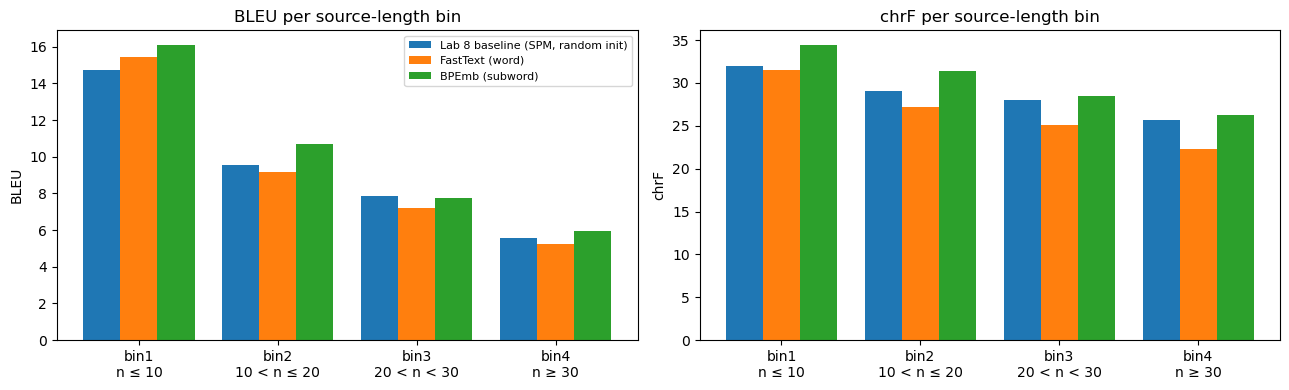

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
names = [k for k in systems]
x = np.arange(len(BINS))
w = 0.8 / len(names)
for ax, (metric, table) in zip(axes, [("BLEU", bleu_table), ("chrF", chrf_table)]):
    for i, name in enumerate(names):
        ax.bar(x + (i - (len(names) - 1) / 2) * w, table.loc[BINS, name], w, label=name)
    ax.set_xticks(x, [f"{b}\n{BIN_LABELS[b]}" for b in BINS])
    ax.set_ylabel(metric); ax.set_title(f"{metric} per source-length bin")
axes[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

### Sentence-level BLEU per bin

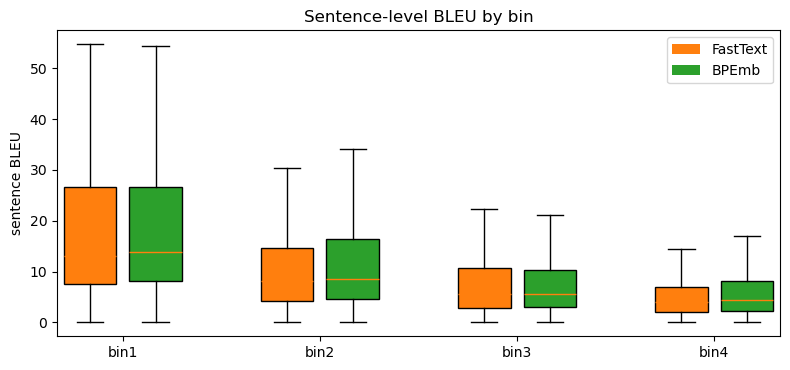

,median sbleu_fasttext,median sbleu_bpemb
bin,,
bin1,13.1,13.8
bin2,8.1,8.5
bin3,5.5,5.6
bin4,3.9,4.3


In [21]:
for col in ("hyp_fasttext", "hyp_bpemb"):
    test["sbleu_" + col[4:]] = [sacrebleu.sentence_bleu(h, [r]).score for h, r in zip(test[col], test.tgt)]

fig, ax = plt.subplots(figsize=(8, 3.8))
pos = np.arange(len(BINS))
for i, (col, color) in enumerate([("sbleu_fasttext", "tab:orange"), ("sbleu_bpemb", "tab:green")]):
    bp = ax.boxplot([test[test.bin == b][col] for b in BINS], positions=pos * 3 + i, widths=0.8,
                    showfliers=False, patch_artist=True)
    for patch in bp["boxes"]:
        patch.set_facecolor(color)
ax.set_xticks(pos * 3 + 0.5, BINS)
ax.legend([plt.Rectangle((0, 0), 1, 1, fc="tab:orange"), plt.Rectangle((0, 0), 1, 1, fc="tab:green")],
          ["FastText", "BPEmb"])
ax.set_ylabel("sentence BLEU"); ax.set_title("Sentence-level BLEU by bin")
plt.tight_layout(); plt.show()
test.groupby("bin")[["sbleu_fasttext", "sbleu_bpemb"]].median().round(1).rename(
    columns=lambda c: "median " + c)

### Sample translations from each bin

In [22]:
samples = test.groupby("bin").sample(2, random_state=RANDOM_SEED).sort_values("bin")
for _, r in samples.iterrows():
    print(f"[{r.bin}]")
    print("  EN      :", r.src)
    print("  REF     :", r.tgt)
    print(f"  FastText: {r.hyp_fasttext}   (sentence BLEU {r.sbleu_fasttext:.1f})")
    print(f"  BPEmb   : {r.hyp_bpemb}   (sentence BLEU {r.sbleu_bpemb:.1f})\n")

[bin1]
  EN      : Shahjahan had constructed the beautiful palace named Shahi Bagh .
  REF     : શાહીબાગ પેલેસ નામક સુંદર મહેલની રચના શાહજહાંએ કરાવી હતી .
  FastText: શાહજહાં બાગને સુંદર મહેલ બનાવ્યો હતો .   (sentence BLEU 5.1)
  BPEmb   : શાહજહાંએ સુંદર બાગનું નિર્માણ કરાવ્યું હતું .   (sentence BLEU 5.6)

[bin1]
  EN      : This disease can cause damage up to 50-60 percent .
  REF     : આ રોગથી ૫૦ - ૬૦ ટકા નુકશાન થઈ શકે છે .
  FastText: આ રોગ ૫૦થી ૫૦ % સુધી થઈ શકે છે .   (sentence BLEU 26.3)
  BPEmb   : આ રોગનું કારણ ૫૦ - ૬૦ ટકા સુધી નુકશાન થઈ શકે છે .   (sentence BLEU 49.7)

[bin2]
  EN      : Although there is not much effect of this on the tourists .
  REF     : જોકે પર્યટકો પર તેની કોઈ વધારે અસર નથી થતી .
  FastText: જોકે આ પર્યટકો પર વધારે અસર નથી થતી .   (sentence BLEU 47.5)
  BPEmb   : જોકે આ પર્યટકો પર વધારે અસર નથી .   (sentence BLEU 21.9)

[bin2]
  EN      : Those divine journalists do n`t want to turn their camera toward 600 villages of homeless tribals in Chattishgardh .


In [23]:
pd.concat({"FastText": res_fasttext, "BPEmb": res_bpemb}).to_csv(f"{ART}/binwise_results.csv")

## 6. Bin-wise result analysis

| Bin | Source length | BLEU: Lab 8 baseline | BLEU: FastText | BLEU: BPEmb | chrF: Lab 8 baseline | chrF: FastText | chrF: BPEmb |
|---|---|---|---|---|---|---|---|
| bin1 | $n \le 10$ | 14.73 | 15.43 | **16.09** | 31.94 | 31.46 | **34.42** |
| bin2 | $10 < n \le 20$ | 9.56 | 9.17 | **10.68** | 29.10 | 27.19 | **31.41** |
| bin3 | $20 < n < 30$ | **7.85** | 7.23 | 7.75 | 28.06 | 25.06 | **28.43** |
| bin4 | $n \ge 30$ | 5.57 | 5.24 | **5.97** | 25.73 | 22.31 | **26.22** |
| overall | all | 8.01 | 7.69 | **8.50** | 27.72 | 25.08 | **28.76** |

- **All three models get worse as sentences get longer.** BLEU roughly halves from bin1 to bin3 and
  drops 2.6–2.9× by bin4, because word order (SVO → SOV) and longer phrases are harder to get right in long
  sentences.
- **BPEmb is the best model overall** (8.50 BLEU / 28.76 chrF) and has the best chrF in every bin. It
  beats the Lab 8 baseline in bins 1, 2 and 4 and roughly ties in bin3 (7.75 vs 7.85). Its pretrained
  subword vectors cover 96–99% of the vocabulary, and subwords can build any word, so it never outputs `<unk>`.
- **FastText helps only on short sentences.** It is second best in bin1 (15.43), but falls below the
  baseline from bin2 onwards, and its chrF is the lowest in every bin. Reasons:
  - *Fixed word vocabulary:* 9–11% of Gujarati test words are outside its 30k vocabulary, and its
    `<unk>` outputs rise sharply with length (1,042 in bin1 → 8,023 in bin4).
  - *Lower coverage:* only 72% (en) / 66% (gu) of vocabulary words have a FastText vector.
  - *Overfitting:* with 27M parameters (vs 14.7M for BPEmb) it early-stopped at step 9,000. Validation
    perplexity was best at step 5,000 (128.4) and rose afterwards; the final checkpoint (step 9,000) was
    used.
- **Outputs are too short.** The brevity penalty is lower for FastText (0.72–0.77) than for BPEmb
  (0.82–0.87), partly because `<unk>` tokens are removed before scoring.
- **Common errors in long sentences:** repeated phrases ("રોગચાળો ફાટી નીકળતો …"), dropped or invented
  names, and some misaligned test pairs that score ≈0 for any output.

**Conclusion:** Pretrained **subword** embeddings (BPEmb) help most: they give the best scores in every
bin except a tie in bin3, especially on chrF. Pretrained **word** embeddings (FastText) help only on short
sentences: unknown words and overfitting hurt them on longer ones. The bin order bin1 > bin2 > bin3 >
bin4 is the same for every model.